# 1. Entendimento do Negócio

Antes de iniciar a exploração dos dados, é necessário compreender o contexto do problema e os objetivos de negócio que motivam esta análise.

O presente estudo busca identificar os fatores que influenciam a satisfação dos clientes de um e-commerce, permitindo que a empresa compreenda melhor os principais pontos de atrito da jornada de compra e desenvolva estratégias capazes de antecipar experiências negativas antes mesmo da realização de pesquisas formais de satisfação.

## 1.1 Problema de Negócio

Um dos principais desafios enfrentados por empresas de e-commerce é compreender a satisfação dos clientes de forma rápida e escalável.

Embora pesquisas de satisfação como o NPS sejam amplamente utilizadas, nem todos os clientes respondem aos questionários, o que reduz a visibilidade da empresa sobre possíveis problemas operacionais.

Neste contexto, o objetivo do projeto é identificar os fatores que estão associados à satisfação dos clientes e desenvolver uma abordagem capaz de antecipar sinais de insatisfação utilizando informações já disponíveis na operação.

## 1.2 Importância do NPS para o Negócio

O Net Promoter Score (NPS) é uma das métricas mais utilizadas para mensurar a satisfação e a fidelidade dos clientes.

A metodologia baseia-se na probabilidade de um consumidor recomendar a empresa para outras pessoas, funcionando como um indicador da qualidade percebida dos serviços prestados.

Clientes satisfeitos tendem a apresentar maior frequência de compra, maior valor ao longo do relacionamento (Lifetime Value) e contribuem para aquisição de novos clientes por meio de indicações espontâneas.

Além disso, o monitoramento do NPS auxilia a empresa na retenção de clientes e na proteção de sua participação de mercado.

## 1.3 Áreas Impactadas Pelos Insights

Os resultados obtidos nesta análise podem contribuir para diferentes áreas da organização.

Na área de logística, os insights podem auxiliar na redução de atrasos, melhoria dos prazos de entrega e otimização dos processos de distribuição.

Para as equipes de atendimento, é possível identificar fatores associados ao aumento das reclamações e ao tempo de resolução de problemas, permitindo ações voltadas à melhoria da experiência dos clientes.

Áreas como marketing e pricing também podem se beneficiar dos resultados, utilizando estratégias de retenção, descontos e ações de recuperação voltadas para clientes com maior risco de insatisfação.

## 1.4 Indicadores Complementares

Além do NPS, outros indicadores podem complementar a análise da experiência do cliente.

Entre os principais indicadores destacam-se:

- Taxa de recompra;
- SLA de entrega;
- Taxa de reclamações;
- Tempo de resolução de chamados;
- CSAT (Customer Satisfaction Score);
- Churn Rate;
- Benchmarks de NPS do setor.

A utilização conjunta dessas métricas permite uma visão mais abrangente da jornada do cliente e dos impactos operacionais sobre a satisfação.

# 2. Definição da Target

Após compreender o contexto de negócio, é necessário definir qual variável será utilizada como principal indicador de satisfação dos clientes ao longo das análises.

## 2.1 Variável Alvo

A variável que selecionamos para representar a satisfação dos clientes é `nps_score`.

Essa variável corresponde à nota de satisfação atribuída pelo cliente após sua experiência de compra e será utilizada como principal indicador ao longo das análises exploratórias.

## 2.2 Justificativa da Escolha

O NPS foi escolhido por ser uma das métricas mais difundidas para avaliação da experiência dos clientes.

Além de permitir comparações com referências de mercado, a métrica oferece uma visão simplificada da percepção dos consumidores sobre os serviços prestados pela empresa.

Seu uso também possibilita identificar fatores que contribuem para a formação de clientes promotores ou detratores.

## 2.3 Momento da Coleta

O NPS é coletado após a conclusão da jornada de compra, quando o cliente já teve contato com os principais processos da empresa, incluindo pedido, entrega e possíveis interações com o atendimento.

Dessa forma, a nota reflete a percepção consolidada da experiência vivenciada pelo consumidor.

## 2.4 Limitações da Variável

Apesar de sua ampla utilização, o NPS apresenta algumas limitações que devem ser consideradas durante a análise.

A principal delas está relacionada à baixa taxa de resposta das pesquisas de satisfação, o que pode introduzir vieses na amostra analisada.

Além disso, clientes com experiências extremamente positivas ou extremamente negativas tendem a responder pesquisas com maior frequência, podendo impactar a representatividade dos resultados observados.

# 3. Conhecimento Inicial da Base de Dados

Antes de iniciar as análises exploratórias, realizamos uma avaliação inicial da estrutura da base de dados. O objetivo desta é compreender a composição dos dados.

A base contém dados relacionados ao perfil do cliente, características dos pedidos, indicadores logísticos, interações com o atendimento e métricas de satisfação.

## 3.1 Carregamento da Base de Dados

Nesta etapa realizamos o carregamento do arquivo CSV disponibilizado para o Tech Challenge. A partir dele serão desenvolvidas todas as análises exploratórias e interpretações de negócio.

Upload da base

In [3]:
from google.colab import files
uploaded = files.upload()

Saving desafio_nps_fase_1.csv to desafio_nps_fase_1.csv


Ler a base

In [4]:
import pandas as pd

df = pd.read_csv("desafio_nps_fase_1.csv")

## 3.2 Primeiras Observações

Visualização inicial para entender quais são as varíaveis da base e como podem auxiliar nas análises.

In [5]:
df.head(20)

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9
5,6,35,Sudeste,75,50006,568.76,6,36.58,3,4,5,41.82,2,2,3,0.9,0,5,1.5
6,7,37,Sudeste,68,50007,41.29,3,99.62,6,8,3,35.83,3,3,4,1.4,0,6,0.6
7,8,60,Sul,37,50008,428.76,4,29.54,10,11,5,44.50,1,0,2,0.0,0,2,4.1
8,9,40,Sul,60,50009,121.56,3,91.95,6,6,3,24.88,2,1,9,6.2,0,3,0.8
9,10,51,Sudeste,70,50010,411.01,6,37.47,3,9,2,30.59,1,0,7,2.7,0,2,4.2


Há informações sobre clientes, pedidos, logística, atendimento e satisfação.

Entre as principais variáveis disponíveis, temos:

- Características dos clientes (idade, região e tempo de relacionamento);
- Informações sobre os pedidos (valor, quantidade de itens e descontos);
- Indicadores logísticos (tempo de entrega, atrasos e tentativas de entrega);
- Indicadores de atendimento (quantidade de contatos, reclamações e tempo de resolução);
- Métricas de satisfação, como CSAT e NPS.

# 4. Entendimento dos Dados (Data Understanding)

Etapa para compreender a dimensão da base e avaliar sua qualidade.

## 4.1 Dimensões da Base

Nesta etapa verificamos a quantidade de registros e variáveis disponíveis para análise.

In [6]:
df.shape

(2500, 19)

A base possui 2.500 registros e 19 variáveis.

O volume de dados é suficiente para identificar padrões de comportamento relacionados à satisfação dos clientes e avaliar possíveis fatores associados ao NPS.

## 4.2 Estrutura e Qualidade dos Dados

A avaliação da estrutura dos dados permite verificar os tipos de variáveis presentes na base e identificar possíveis problemas de qualidade, como valores ausentes ou inconsistências.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   object 
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64

Verificou-se que todas as 19 variáveis possuem 2.500 registros válidos, indicando ausência de valores nulos.

Esse resultado reduz a necessidade de tratamentos relacionados à imputação de dados e aumenta a confiabilidade das análises.

A base contém tanto variáveis numéricas quanto categóricas (Região), permitindo investigar fatores relacionados a diferentes etapas da jornada do cliente.

### 4.2.1 Verificação de registros duplicados em clientes e pedidos

In [8]:
df['customer_id'].duplicated().sum()

np.int64(0)

In [20]:
df['order_id'].duplicated().sum()

np.int64(0)

Avaliando o conjunto de clientes e de pedidos, não foram detectados clientes ou pedidos duplicados. Ambos possuem apenas registros únicos.

## 4.3 Hipóteses Iniciais de Negócio

Com base no contexto apresentado pelo desafio, foram formuladas algumas hipóteses iniciais que serão investigadas ao longo da análise.

### Hipótese 1
Atrasos na entrega reduzem a satisfação dos clientes.

### Hipótese 2
Maior quantidade de reclamações está associada a níveis mais baixos de NPS.

### Hipótese 3
Clientes que precisam entrar em contato com o suporte tendem a apresentar experiências menos satisfatórias.

### Hipótese 4
Clientes mais satisfeitos apresentam maior probabilidade de realizar novas compras.

## 4.4 Estatísticas Descritivas

As estatísticas descritivas permitem compreender o comportamento geral das variáveis numéricas presentes na base, identificando tendências centrais, dispersão e possíveis valores extremos.

In [9]:
df.describe()

,customer_id,customer_age,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
count,2500.00000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,1250.50000,43.396000,61.322400,51250.50000,434.259740,3.470800,29.745620,6.004000,8.022000,2.187200,38.217016,2.005600,1.519600,5.485600,4.378600,0.087200,4.150400,2.941600
std,721.83216,14.888487,34.478729,721.83216,289.772497,1.687331,29.225603,3.159743,3.770411,1.454442,12.076074,0.815497,1.231512,3.458002,2.510229,0.282184,1.784223,2.378957
min,1.00000,18.000000,1.000000,50001.00000,7.760000,1.000000,0.020000,1.000000,2.000000,0.000000,2.620000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,625.75000,31.000000,31.000000,50625.75000,220.245000,2.000000,8.885000,3.000000,5.000000,1.000000,29.927500,1.000000,1.000000,2.000000,2.600000,0.000000,3.000000,0.700000
50%,1250.50000,43.000000,62.000000,51250.50000,375.515000,3.000000,20.935000,6.000000,8.000000,2.000000,38.500000,2.000000,1.000000,6.000000,4.400000,0.000000,4.000000,2.800000
75%,1875.25000,56.000000,91.000000,51875.25000,577.290000,5.000000,40.832500,9.000000,11.000000,3.000000,46.270000,3.000000,2.000000,8.000000,6.100000,0.000000,5.000000,4.800000
max,2500.00000,69.000000,119.000000,52500.00000,1983.810000,6.000000,230.330000,11.000000,14.000000,8.000000,76.130000,3.000000,7.000000,11.000000,10.000000,1.000000,11.000000,10.000000


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,2500.0,1250.500000,721.832160,1.00,625.7500,1250.500,1875.2500,2500.00
customer_age,2500.0,43.396000,14.888487,18.00,31.0000,43.000,56.0000,69.00
customer_tenure_months,2500.0,61.322400,34.478729,1.00,31.0000,62.000,91.0000,119.00
order_id,2500.0,51250.500000,721.832160,50001.00,50625.7500,51250.500,51875.2500,52500.00
order_value,2500.0,434.259740,289.772497,7.76,220.2450,375.515,577.2900,1983.81
items_quantity,2500.0,3.470800,1.687331,1.00,2.0000,3.000,5.0000,6.00
discount_value,2500.0,29.745620,29.225603,0.02,8.8850,20.935,40.8325,230.33
payment_installments,2500.0,6.004000,3.159743,1.00,3.0000,6.000,9.0000,11.00
delivery_time_days,2500.0,8.022000,3.770411,2.00,5.0000,8.000,11.0000,14.00
delivery_delay_days,2500.0,2.187200,1.454442,0.00,1.0000,2.000,3.0000,8.00


A média do NPS observada na base é de aproximadamente 4,38 pontos, valor considerado baixo em termos de satisfação do cliente.

Também foi identificada uma baixa taxa de recompra em até 30 dias, próxima de 8,7%.

Do ponto de vista operacional, observam-se atrasos médios superiores a dois dias, além de um volume relevante de reclamações e contatos com o atendimento.

**Esses resultados sugerem que problemas logísticos e de suporte ao cliente podem exercer influência significativa sobre a percepção da experiência de compra.**

# 5. Análise Exploratória dos Dados (EDA)

## 5.1 Distribuição das Notas de NPS

**O primeiro passo da análise exploratória consiste em compreender como os clientes avaliam sua experiência de compra.**

A análise da distribuição do NPS permite identificar o comportamento geral da satisfação dos consumidores, verificar a presença de grupos de clientes extremamente satisfeitos ou insatisfeitos e estabelecer um ponto de partida para as investigações subsequentes.

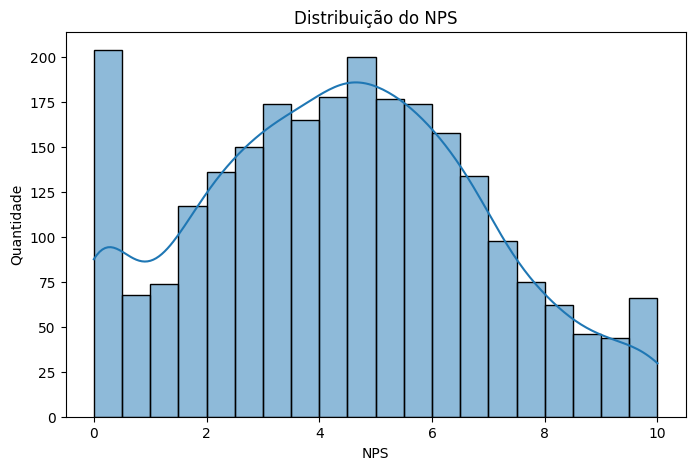

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    df['nps_score'],
    bins=20,
    kde=True
)

plt.title('Distribuição do NPS')
plt.xlabel('NPS')
plt.ylabel('Quantidade')

plt.show()

A distribuição das notas de NPS apresenta concentração significativa entre valores próximos de 3 e 6 pontos, indicando que grande parte dos clientes possui níveis moderados ou baixos de satisfação.

A média observada do NPS foi de aproximadamente 4,38 pontos, valor considerado relativamente baixo para indicadores de experiência do cliente.

Também chama atenção a elevada frequência de avaliações próximas de zero, sugerindo a presença de um grupo relevante de clientes altamente insatisfeitos e potencialmente classificados como detratores.

Embora existam clientes com avaliações elevadas, próximas de 9 e 10 pontos, sua participação é menor quando comparada às avaliações intermediárias e baixas.

De forma geral, os resultados indicam que os desafios relacionados à experiência do cliente não parecem estar concentrados em casos isolados, mas possivelmente refletem questões operacionais recorrentes ao longo da jornada de compra.

## 5.2 Correlação entre Variáveis

Após compreender a distribuição das notas, vamos investigar quais variáveis apresentam maior associação com a satisfação dos clientes.

A análise de correlação permite identificar relações entre variáveis, indicando quais fatores tendem a variar em conjunto com o NPS. Embora correlação não signifique causalidade, essa técnica é útil para direcionar investigações e apoiar a identificação dos fatores mais relevantes para a experiência do cliente.

O objetivo desta etapa é responder uma das principais perguntas deste estudo:

**Quais fatores operacionais parecem mais críticos para a satisfação dos clientes?**


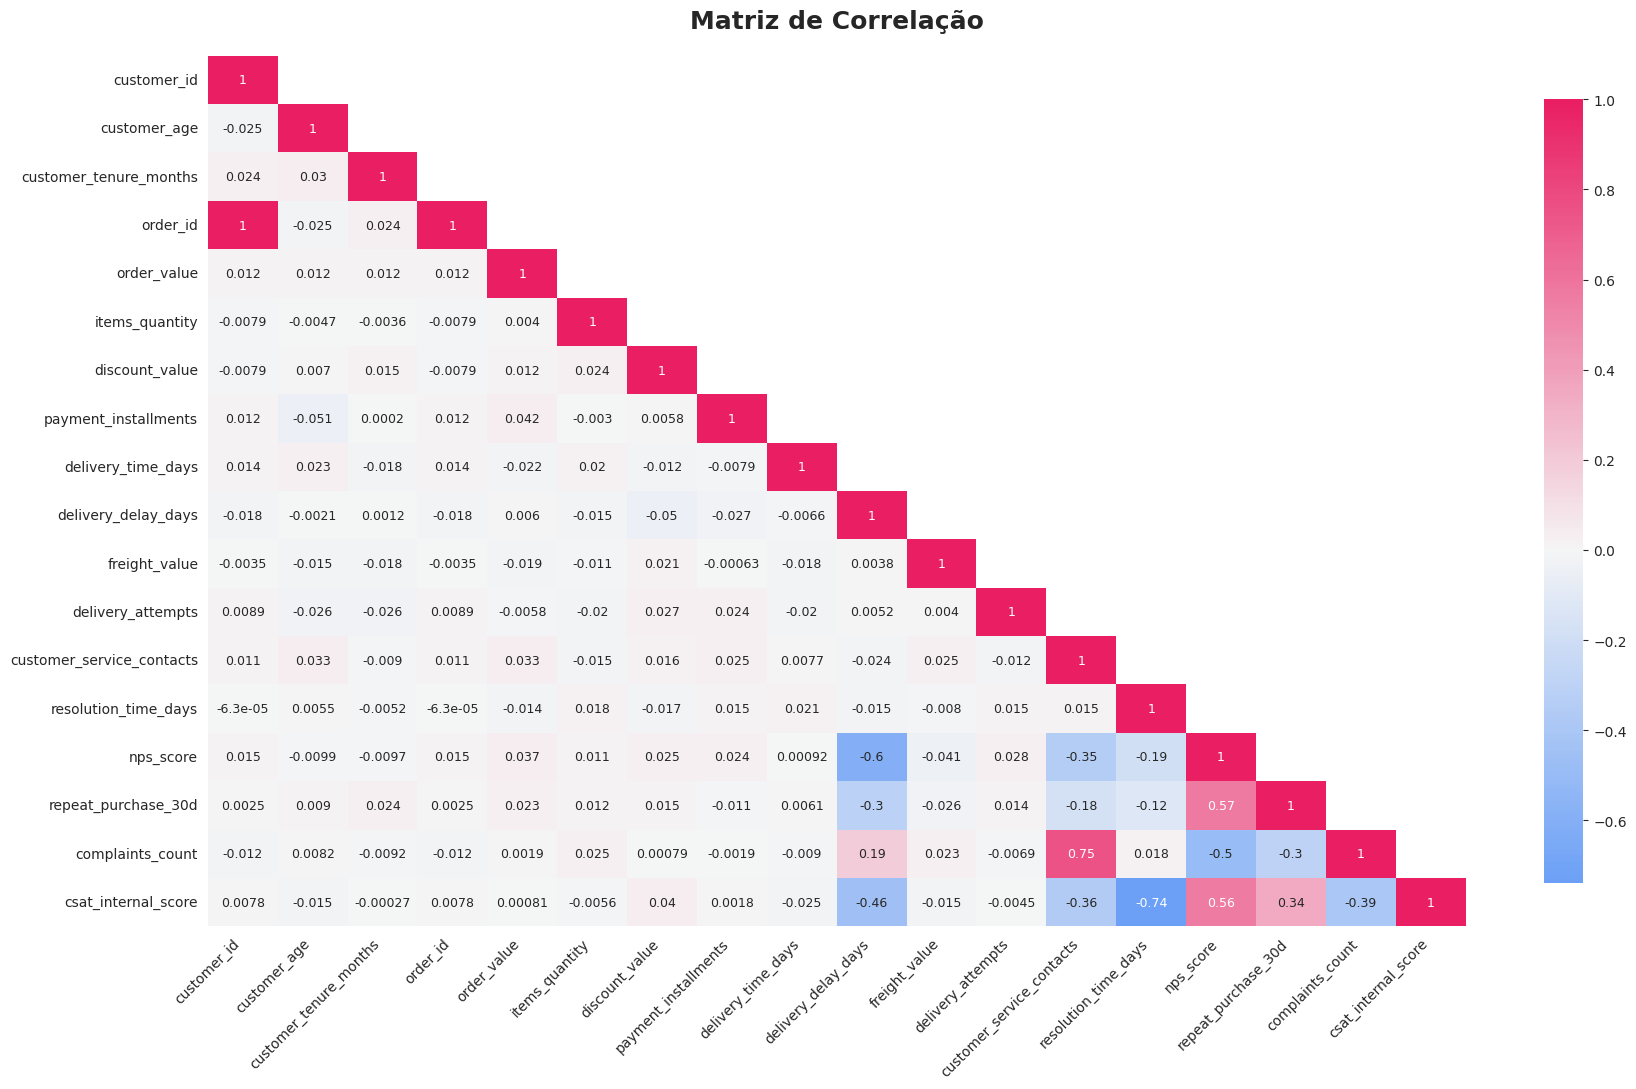

In [12]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sns.set_style("white")

corr = df.corr(numeric_only=True)

mask = np.triu(
    np.ones_like(corr, dtype=bool),
    k=1
)

custom_cmap = LinearSegmentedColormap.from_list(
    "techchallenge",
    [
        "#3B82F6",
        "#F5F5F5",
        "#E91E63"
    ]
)

fig, ax = plt.subplots(figsize=(18,11))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2g",
    cmap=custom_cmap,
    center=0,
    linewidths=0,
    cbar_kws={"shrink":0.9},
    annot_kws={"size":9},
    ax=ax
)

ax.grid(False)

plt.title(
    "Matriz de Correlação",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


A análise da matriz de correlação demonstra que os fatores mais associados ao NPS estão relacionados principalmente à logística e ao atendimento ao cliente.

Entre as variáveis analisadas, o atraso na entrega (`delivery_delay_days`) apresentou a associação negativa mais forte com o NPS, indicando que questões logísticas exercem influência significativa sobre a percepção da experiência do cliente.

Também foram observadas correlações negativas relevantes entre a satisfação dos consumidores e as seguintes variáveis:

- Dias de atraso na entrega (`delivery_delay_days`);
- Quantidade de reclamações registradas (`complaints_count`);
- Número de contatos com o atendimento (`customer_service_contacts`);
- Tempo de resolução de problemas (`resolution_time_days`).

Esses resultados sugerem que experiências negativas relacionadas à entrega e ao suporte possuem forte influência sobre os níveis de satisfação dos clientes.

Além da relação com o NPS, observou-se uma forte associação entre a quantidade de reclamações e o número de contatos realizados com o atendimento, indicando que problemas operacionais tendem a gerar maior demanda sobre os canais de suporte da empresa.

Por outro lado, foi identificada uma correlação positiva relevante entre o NPS e a recompra em até 30 dias (`repeat_purchase_30d`), sugerindo que clientes mais satisfeitos apresentam maior probabilidade de continuar comprando da empresa.

Esse resultado reforça a importância estratégica da experiência do cliente, uma vez que melhorias nos níveis de satisfação podem contribuir não apenas para a percepção da marca, mas também para retenção de clientes e geração de receita.

### Correlações Específicas com o NPS

Para aprofundar a análise, foi realizado um ranking das variáveis mais associadas ao NPS.

Essa abordagem permite identificar de forma mais objetiva quais fatores apresentam maior potencial de impacto sobre a satisfação dos clientes.

In [13]:
corr_nps = (
    df.corr(numeric_only=True)['nps_score']
    .sort_values()
)

corr_nps

,nps_score
delivery_delay_days,-0.597260
complaints_count,-0.496800
customer_service_contacts,-0.350845
resolution_time_days,-0.191392
freight_value,-0.041087
customer_age,-0.009936
customer_tenure_months,-0.009711
delivery_time_days,0.000925
items_quantity,0.011468
customer_id,0.015162


A análise das correlações específicas com o NPS permite identificar de forma objetiva quais fatores apresentam maior associação com a satisfação dos clientes.

A variável com maior correlação negativa foi o atraso na entrega (`delivery_delay_days`), com aproximadamente -0,60, indicando que problemas logísticos representam o principal fator associado à redução da satisfação dos consumidores.

Em seguida, destacam-se:

- Quantidade de reclamações registradas (`complaints_count`), com correlação próxima de -0,50;
- Número de contatos realizados com o atendimento (`customer_service_contacts`), com correlação próxima de -0,35;
- Tempo para resolução de problemas (`resolution_time_days`), apresentando correlação negativa mais moderada.

Esses resultados reforçam a hipótese de que experiências negativas relacionadas à logística e ao atendimento exercem impacto relevante na percepção dos clientes.

Entre os fatores positivamente associados ao NPS, destacam-se:

- Recompra em até 30 dias (`repeat_purchase_30d`), com correlação próxima de 0,57;
- CSAT interno da empresa (`csat_internal_score`), com correlação próxima de 0,56.

A forte associação observada entre satisfação e recompra sugere que clientes mais satisfeitos apresentam maior probabilidade de manter relacionamento com a empresa, evidenciando o impacto da experiência do cliente sobre indicadores relevantes de negócio.

Outro resultado importante foi a baixa associação entre o NPS e variáveis financeiras, como valor do pedido, quantidade de itens, descontos e parcelamento. Isso sugere que a satisfação dos clientes parece ser influenciada principalmente por aspectos operacionais da jornada de compra, e não pelas características econômicas dos pedidos.

## 5.3 O que gera detratores ?

Após identificar as variáveis mais associadas ao NPS, o próximo passo consiste em investigar quais fatores estão mais presentes nas experiências negativas dos clientes.

O objetivo desta análise é compreender quais características operacionais tendem a estar associadas aos menores níveis de satisfação e quais aspectos da jornada merecem maior atenção da empresa.

Neste contexto, serão avaliados especialmente os impactos dos atrasos nas entregas e da quantidade de reclamações registradas pelos clientes.

### 5.3.1 Relação entre atraso e satisfação

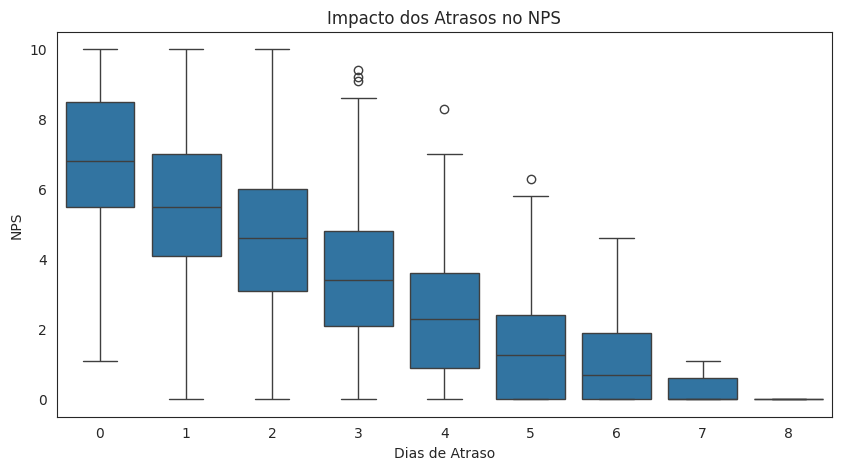

In [14]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='delivery_delay_days',
    y='nps_score'
)

plt.title('Impacto dos Atrasos no NPS')
plt.xlabel('Dias de Atraso')
plt.ylabel('NPS')

plt.show()

Observa-se uma relação clara entre o aumento dos dias de atraso e a redução das notas de NPS.

Clientes que receberam seus pedidos sem atraso apresentam níveis significativamente mais elevados de satisfação, com medianas próximas de 7 pontos. Em contrapartida, à medida que os atrasos aumentam, observa-se uma queda consistente das avaliações realizadas pelos consumidores.

A partir de aproximadamente 4 dias de atraso, as notas de NPS passam a se concentrar em níveis mais baixos, sugerindo que atrasos prolongados possuem impacto expressivo na percepção da experiência de compra.

Esse comportamento reforça os resultados identificados anteriormente na análise de correlação e evidencia a relevância dos processos logísticos para a satisfação dos clientes.

**Os resultados indicam que o atraso na entrega é um dos principais fatores associados à formação de detratores, representando uma oportunidade prioritária de melhoria para a empresa.**

### 5.3.2 Relação entre reclamações e *satisfação*

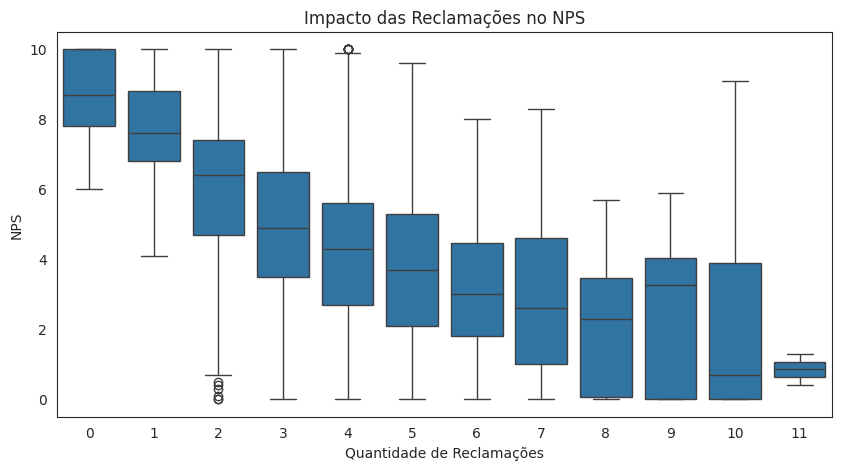

In [15]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='complaints_count',
    y='nps_score'
)

plt.title('Impacto das Reclamações no NPS')
plt.xlabel('Quantidade de Reclamações')
plt.ylabel('NPS')

plt.show()

Observa-se uma relação clara entre o aumento da quantidade de reclamações e a redução das notas de NPS.

Clientes que não registraram reclamações apresentam os maiores níveis de satisfação, com medianas próximas das avaliações mais altas da escala. Em contrapartida, conforme aumenta o volume de reclamações registradas, observa-se uma redução gradual das notas atribuídas pelos consumidores.

Os resultados indicam que a recorrência de problemas ao longo da jornada do cliente possui forte impacto sobre a percepção da qualidade do serviço, contribuindo diretamente para a formação de avaliações negativas.

Embora exista alguma variabilidade entre os grupos analisados, a tendência geral observada reforça que clientes que enfrentam mais problemas tendem a apresentar níveis significativamente menores de satisfação.

**A quantidade de reclamações surge como um importante indicador de risco para identificação antecipada de clientes potencialmente insatisfeitos e representa uma importante oportunidade para ações preventivas por parte da empresa.**

## 5.4 Existe um ponto de ruptura na experiência?

Além de identificar fatores associados à satisfação, é importante verificar se existem limites operacionais a partir dos quais a experiência do cliente sofre deterioração significativa.

Esta análise busca identificar possíveis pontos de ruptura relacionados aos atrasos nas entregas e à quantidade de reclamações.

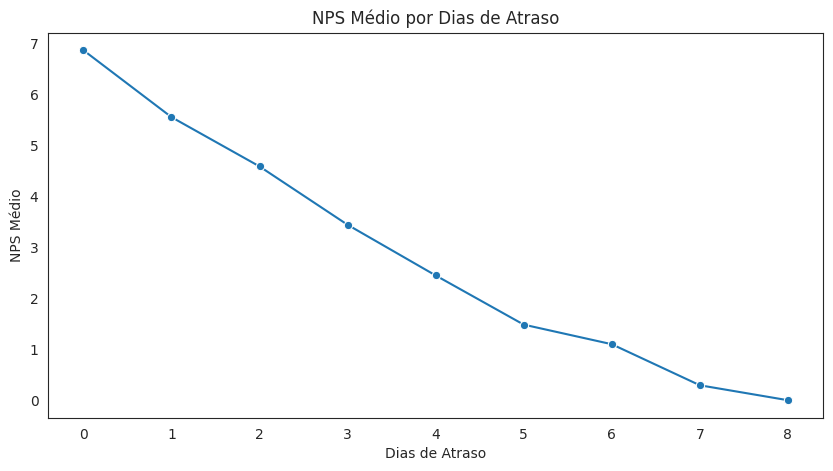

In [16]:
nps_delay = (
    df.groupby('delivery_delay_days')['nps_score']
      .mean()
      .reset_index()
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=nps_delay,
    x='delivery_delay_days',
    y='nps_score',
    marker='o'
)

plt.title('NPS Médio por Dias de Atraso')
plt.xlabel('Dias de Atraso')
plt.ylabel('NPS Médio')

plt.show()

A análise do NPS médio por dias de atraso evidencia uma relação inversa clara entre desempenho logístico e satisfação dos clientes.

Observa-se uma redução contínua das notas de NPS à medida que o número de dias de atraso aumenta. Enquanto clientes que receberam seus pedidos sem atraso apresentaram NPS médio próximo de 7 pontos, aqueles que enfrentaram atrasos mais elevados registraram níveis significativamente inferiores de satisfação.

O gráfico sugere a existência de um possível ponto de ruptura a partir de aproximadamente 4 a 5 dias de atraso, momento em que as avaliações passam a apresentar queda mais acentuada e passam a se concentrar em níveis muito baixos.

Esse comportamento reforça a importância da logística para a experiência do cliente e sugere que atrasos superiores a esse intervalo podem comprometer significativamente a percepção de qualidade do serviço.

**Os resultados indicam que o controle dos atrasos de entrega deve ser tratado como uma prioridade operacional, uma vez que pequenas variações no prazo já demonstram impacto relevante nos níveis de satisfação dos consumidores.**

## 5.5 Perfil dos Clientes Mais Satisfeitos

Nesta etapa são analisadas características dos clientes para identificar possíveis diferenças nos níveis de satisfação entre regiões geográficas, perfis demográficos e tempo de relacionamento com a empresa.

O objetivo é verificar se determinados grupos apresentam padrões distintos de experiência.

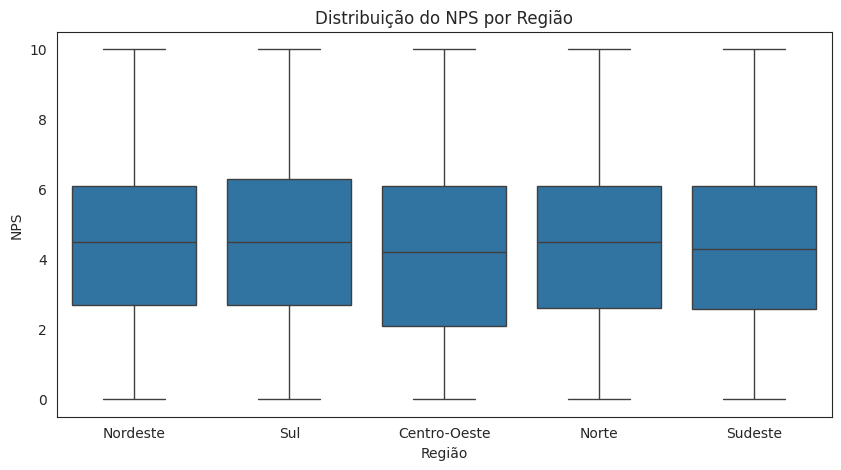

In [17]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='customer_region',
    y='nps_score'
)

plt.title('Distribuição do NPS por Região')
plt.xlabel('Região')
plt.ylabel('NPS')

plt.show()


A análise regional demonstra que os níveis de satisfação apresentam comportamento relativamente semelhante entre as diferentes regiões avaliadas.

As distribuições observadas possuem medianas próximas e padrões de dispersão comparáveis, não sendo identificadas diferenças expressivas que indiquem uma região significativamente mais satisfeita ou mais insatisfeita que as demais.

Esse resultado sugere que o NPS não parece ser fortemente influenciado pela localização geográfica dos clientes dentro da base analisada.

Quando comparado aos fatores identificados anteriormente, como atrasos na entrega, quantidade de reclamações e interações com o atendimento, o fator regional demonstra menor potencial explicativo para as variações observadas na satisfação dos consumidores.

**Os resultados indicam que os principais desafios relacionados ao NPS estão mais associados a processos operacionais da empresa do que a características geográficas dos clientes.**

## 5.6 Relação entre Recompra e Satisfação

Uma das hipóteses centrais deste estudo é que clientes mais satisfeitos possuem maior probabilidade de voltar a comprar.

Para avaliar essa hipótese, foi analisada a distribuição do NPS considerando a ocorrência ou não de recompra em até 30 dias.

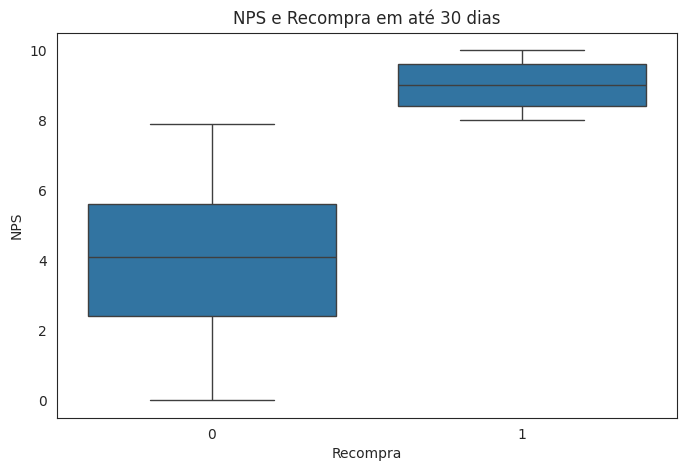

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='repeat_purchase_30d',
    y='nps_score'
)

plt.title('NPS e Recompra em até 30 dias')
plt.xlabel('Recompra')
plt.ylabel('NPS')

plt.show()

## 5.7 Classificação Tradicional do NPS


A análise demonstra uma diferença expressiva entre os níveis de satisfação dos clientes que realizaram recompra e daqueles que não retornaram à empresa.

Observa-se que os clientes que efetuaram uma nova compra em até 30 dias apresentam notas de NPS substancialmente mais elevadas, com valores concentrados nas faixas superiores da escala de satisfação.

Por outro lado, os clientes que não realizaram recompra apresentam maior dispersão das avaliações e níveis médios de satisfação significativamente inferiores.

Esse resultado reforça a hipótese levantada ao longo do estudo de que a experiência do cliente possui relação direta com sua permanência e fidelização.

**A forte associação entre satisfação e recompra sugere que melhorias na experiência do cliente podem gerar impactos não apenas na percepção da marca, mas também em indicadores estratégicos de negócio, como retenção, recorrência de compras e geração de receita.**

In [19]:
import pandas as pd
import os

# Caminho do arquivo
file_path = 'desafio_nps_fase_1.csv'

if not os.path.exists(file_path):
    print("ATENÇÃO: O arquivo 'desafio_nps_fase_1.csv' não foi encontrado no diretório atual.")
    print("Por favor, execute a célula de upload no topo do notebook (célula UXD-iLL4kX2E) ou envie o arquivo novamente.")
else:
    df = pd.read_csv(file_path)

    def classificar_nps(nota):
        if nota >= 9:
            return 'Promotor'
        elif nota >= 7:
            return 'Neutro'
        else:
            return 'Detrator'

    # Criando a coluna de classificação de acordo com a nota de NPS
    df['nps_classification'] = df['nps_score'].apply(classificar_nps)

    # Calculando a distribuição percentual
    distribuicao_nps = df['nps_classification'].value_counts(normalize=True) * 100

    # Calculando o score NPS Geral: % Promotores - % Detratores
    nps_geral = distribuicao_nps.get('Promotor', 0) - distribuicao_nps.get('Detrator', 0)

    print("Distribuição das Categorias de NPS:")
    for cat, perc in distribuicao_nps.items():
        print(f"- {cat}s: {perc:.2f}%")

    print(f"\nNPS Geral da Base: {nps_geral:.2f}")

Distribuição das Categorias de NPS:
- Detrators: 84.36%
- Neutros: 11.24%
- Promotors: 4.40%

NPS Geral da Base: -79.96


Os resultados demonstram predominância significativa de clientes classificados como detratores na base analisada.

O NPS geral calculado apresentou valor negativo, indicando que a quantidade de clientes insatisfeitos é superior à quantidade de clientes promotores.

Esse resultado é consistente com as análises anteriores e reforça a necessidade de melhorias operacionais voltadas principalmente à logística e ao atendimento ao cliente.

# 6. Principais Insights

Após a realização das análises exploratórias, foi possível consolidar os principais achados da investigação. Os resultados reforçam a importância dos fatores operacionais na experiência do cliente e demonstram como problemas ao longo da jornada afetam diretamente os níveis de satisfação e a recompra.

Os principais insights identificados foram:

1. O atraso na entrega foi o fator operacional mais associado à insatisfação dos clientes.

2. O aumento da quantidade de reclamações está relacionado à redução das notas de NPS.

3. Clientes que precisam interagir frequentemente com o atendimento tendem a relatar experiências menos satisfatórias.

4. A satisfação dos clientes demonstrou relação positiva com a recompra em até 30 dias.

5. Os fatores operacionais da jornada possuem maior influência sobre o NPS do que características financeiras dos pedidos.



# 7. Recomendações de Negócio

Com base nas análises realizadas, foram identificadas oportunidades de melhoria relacionadas principalmente à logística e ao atendimento ao cliente.

## Melhorar o desempenho logístico

Os resultados demonstraram que o atraso na entrega apresenta a associação negativa mais forte com o NPS. Dessa forma, iniciativas voltadas à redução dos atrasos possuem potencial para gerar impactos significativos na satisfação dos consumidores.

## Implementar monitoramento preventivo

Clientes que apresentam múltiplas reclamações ou atrasos recorrentes podem ser identificados antecipadamente como clientes de risco, permitindo atuação preventiva antes da aplicação da pesquisa de NPS.

## Criar estratégias de recuperação

Ações como cupons de desconto, frete gratuito ou comunicação proativa podem auxiliar na recuperação de clientes impactados por atrasos ou problemas operacionais.

## Reduzir o tempo de resolução de problemas

Melhorias nos processos de atendimento podem contribuir para redução da insatisfação e melhoria da experiência geral dos consumidores.

# 8. Conclusão

A análise realizada permitiu identificar os principais fatores associados à satisfação dos clientes em uma operação de e-commerce.

Os resultados demonstraram que fatores operacionais, especialmente relacionados à logística e ao atendimento, possuem maior influência sobre o NPS do que características financeiras dos pedidos.

O atraso na entrega foi identificado como o principal fator associado à redução da satisfação, seguido pelo volume de reclamações e pela necessidade de interação com o suporte.

Além disso, observou-se uma relação positiva entre satisfação e recompra, sugerindo que melhorias na experiência do cliente podem gerar impactos relevantes para retenção, fidelização e geração de receita.

De forma geral, os resultados indicam que investimentos em logística, atendimento e ações preventivas de relacionamento possuem elevado potencial para melhorar a experiência do cliente e fortalecer os resultados do negócio.